# Activité Pratique N°4 — Architecture Transformer
## Partie 1 — Étape 1 : Générer le dataset (série temporelle)

**IA Générative Multi Modale — 5IAD G1, EMSI** · Étudiant : BENHAYOUN SADAFI Mohamed

Série temporelle $s = \sin(x)$, rangée en petites séquences de 10 valeurs.

On prend **200 valeurs de $x$ entre 0 et 20** et on calcule $s_t = \sin(x_t)$.
La série est rangée en **séquences de 10 valeurs** (fenêtre glissante) ; la cible de chaque séquence est la valeur suivante :

$$
X = \big[[s_0,\dots,s_9],\ [s_1,\dots,s_{10}],\ [s_2,\dots,s_{11}],\ \dots\big]
\qquad
Y = \big[s_{10},\ s_{11},\ s_{12},\ \dots\big]
$$

On obtient $200 - 10 = 190$ exemples : les **150 premiers** pour l'entraînement, les **40 derniers** pour le test (découpage chronologique, sans mélange).

In [1]:
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn


def fixer_graine(graine=42):
    random.seed(graine)
    np.random.seed(graine)
    torch.manual_seed(graine)


fixer_graine()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| appareil :", device,
      f"({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "")

PyTorch 2.14.1+cu126 | appareil : cuda (NVIDIA GeForce MX450)


In [2]:
x = torch.linspace(0, 20, 200)
s = torch.sin(x)
longueur_sequence = 10

X = torch.stack([s[i:i + longueur_sequence] for i in range(len(s) - longueur_sequence)])
Y = torch.stack([s[i + longueur_sequence] for i in range(len(s) - longueur_sequence)])
print("Avant unsqueeze : X", tuple(X.shape), "| Y", tuple(Y.shape))

# Forme attendue par les couches récurrentes : (séquences, longueur, variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
Y = Y.unsqueeze(-1)  # (190, 1)
print("Après unsqueeze : X", tuple(X.shape), "| Y", tuple(Y.shape))

X_train, Y_train = X[:150], Y[:150]
X_test, Y_test = X[150:], Y[150:]
print("\nTrain :", tuple(X_train.shape), tuple(Y_train.shape))
print("Test  :", tuple(X_test.shape), tuple(Y_test.shape))

Avant unsqueeze : X (190, 10) | Y (190,)
Après unsqueeze : X (190, 10, 1) | Y (190, 1)

Train : (150, 10, 1) (150, 1)
Test  : (40, 10, 1) (40, 1)


In [3]:
for i in range(3):
    print(f"X[{i}] = {[round(v, 3) for v in X[i, :, 0].tolist()]}  ->  Y[{i}] = {Y[i, 0].item():.3f} (= s_{i + 10})")

X[0] = [0.0, 0.1, 0.2, 0.297, 0.391, 0.482, 0.567, 0.647, 0.72, 0.786]  ->  Y[0] = 0.844 (= s_10)
X[1] = [0.1, 0.2, 0.297, 0.391, 0.482, 0.567, 0.647, 0.72, 0.786, 0.844]  ->  Y[1] = 0.894 (= s_11)
X[2] = [0.2, 0.297, 0.391, 0.482, 0.567, 0.647, 0.72, 0.786, 0.844, 0.894]  ->  Y[2] = 0.934 (= s_12)


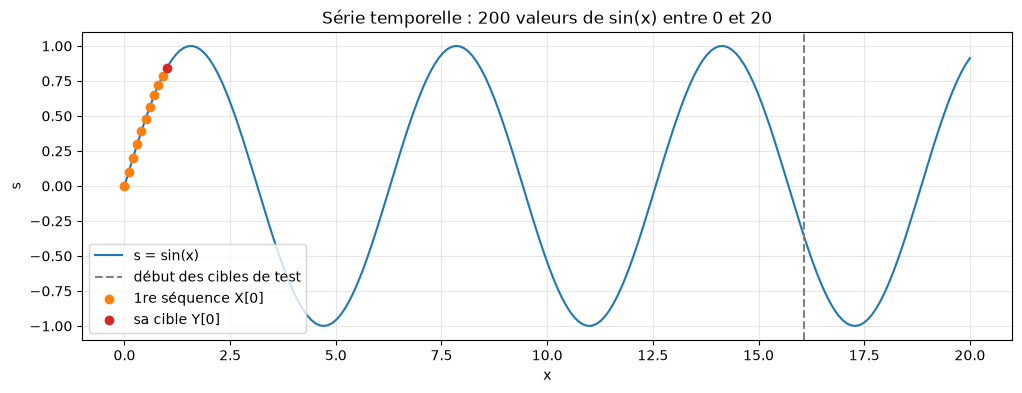

In [4]:
plt.figure(figsize=(12, 4))
plt.plot(x, s, label="s = sin(x)")
plt.axvline(x[150 + longueur_sequence].item(), color="gray", linestyle="--", label="début des cibles de test")
plt.scatter(x[:10], s[:10], color="tab:orange", zorder=3, label="1re séquence X[0]")
plt.scatter(x[10], s[10], color="tab:red", zorder=3, label="sa cible Y[0]")
plt.xlabel("x")
plt.ylabel("s")
plt.title("Série temporelle : 200 valeurs de sin(x) entre 0 et 20")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**À retenir :** chaque exemple est une fenêtre de 10 valeurs consécutives et sa cible est la valeur suivante.
Ce même dataset est refait au début des notebooks 2 (RNN), 3 (LSTM) et 4 (Transformer).